# 05. Modelo DenseNet121

Este cuaderno adapta una DenseNet121 preentrenada en ImageNet para estimar la magnitud del dano por
sequia a partir de la fotografia RGB. La red conserva sus bloques densos y reemplaza la capa de
clasificacion por una capa lineal de una neurona que predice `magnitud / 100`. Toda la logica de
entrenamiento esta en `src.modelos_densenet`; el cuaderno solo la ejecuta y documenta el resultado.

## Entorno

In [1]:
import sys
from pathlib import Path


def raiz_proyecto():
    for candidato in [Path.cwd(), *Path.cwd().parents]:
        if (candidato / "src").is_dir():
            return candidato
    raise RuntimeError("No se encontro la raiz del proyecto")


RAIZ = raiz_proyecto()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)

import torch
from matplotlib.ticker import MaxNLocator

from src.config import PALETA
from src.conjunto import cargar_conjunto
from src.evaluacion import cargar_resultados, metricas, tabla_predicciones
from src.graficos import aplicar_estilo, guardar_figura
from src.modelos_densenet import EPOCAS_MAXIMAS, PACIENCIA, TAMANO_LOTE, dispositivo, ejecutar_densenet
from src.particiones import entrenamiento_y_prueba

aplicar_estilo()
nombre_gpu = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "sin GPU CUDA"
print(f"torch {torch.__version__}, dispositivo: {dispositivo().type} ({nombre_gpu})")

torch 2.14.1+cu130, dispositivo: cuda (NVIDIA GeForce RTX 4050 Laptop GPU)


## Procedimiento

El procedimiento es el mismo que el de ResNet50, para que la comparacion refleje la arquitectura y no
diferencias de configuracion:

| Elemento | Valor |
|:--|:--|
| Pesos iniciales | ImageNet (`IMAGENET1K_V1`) de `torchvision` |
| Evaluacion | `Resize(256)`, `CenterCrop(224)` y normalizacion de ImageNet |
| Aumentos | `RandomResizedCrop(224, scale=(0.7, 1.0))` y `RandomHorizontalFlip`, sin alterar el color |
| Objetivo y salida | `magnitud / 100` con una capa lineal de una neurona |
| Perdida y optimizador | `MSELoss` y `AdamW` con `weight_decay=1e-4` |
| Lote | 16 con precision mixta |
| Epocas | Maximo 15 con parada temprana de paciencia 3 sobre la perdida de validacion |
| Busqueda | Tasa de aprendizaje `1e-4` y `3e-4`; descongelar `cabeza` o `ultimo_bloque` |

En DenseNet121, `cabeza` entrena solo la capa lineal de salida y `ultimo_bloque` entrena ademas el
cuarto bloque denso (`denseblock4`) y la normalizacion final (`norm5`). La parte congelada queda en
modo de evaluacion para que sus capas de normalizacion conserven las estadisticas de ImageNet.

La validacion usa el primer pliegue de `pliegues_por_campo`, de modo que ningun campo aparece a ambos
lados. Se elige la configuracion con menor RMSE de validacion y se reentrena con todo el
entrenamiento DR durante las epocas elegidas. El subconjunto de prueba se usa una sola vez al final.

In [2]:
conjunto = cargar_conjunto()
entrenamiento, prueba = entrenamiento_y_prueba(conjunto, solo_dr=True)
print(f"registros DR de entrenamiento: {len(entrenamiento)}, campos: {entrenamiento['id_campo'].nunique()}")
print(f"registros DR de prueba: {len(prueba)}")
print(f"lote: {TAMANO_LOTE}, epocas maximas: {EPOCAS_MAXIMAS}, paciencia: {PACIENCIA}")

registros DR de entrenamiento: 3655, campos: 1453
registros DR de prueba: 834
lote: 16, epocas maximas: 15, paciencia: 3


## Ajuste y entrenamiento

In [3]:
ruta = ejecutar_densenet(conjunto)
resultados = cargar_resultados("densenet121")
print(f"resultados guardados en: {ruta}")
print(f"tiempo de entrenamiento: {resultados.tiempo_entrenamiento_s / 60:.1f} min")
print(f"tiempo de inferencia: {resultados.tiempo_inferencia_ms:.2f} ms por imagen")
resultados.hiperparametros

Dispositivo: cuda. Ajuste: 2924, validacion: 731, prueba DR: 834
Configuracion: tasa=0.0001, descongelar=cabeza


  epoca 1: {'epoca': 1, 'perdida_entrenamiento': 0.14591700270792365, 'perdida_validacion': 0.07508747552899916, 'mae_validacion': 21.802379018467853} (38 s)


  epoca 2: {'epoca': 2, 'perdida_entrenamiento': 0.07429157888514236, 'perdida_validacion': 0.061362747566933114, 'mae_validacion': 19.591503639064637} (7 s)


  epoca 3: {'epoca': 3, 'perdida_entrenamiento': 0.0637338119068485, 'perdida_validacion': 0.055613556613562126, 'mae_validacion': 18.739703344091996} (8 s)


  epoca 4: {'epoca': 4, 'perdida_entrenamiento': 0.057517587893964814, 'perdida_validacion': 0.05124156201596241, 'mae_validacion': 17.610077655755706} (7 s)


...

  epoca 12: {'epoca': 12, 'perdida_entrenamiento': 0.035875621539949554} (9 s)


  epoca 13: {'epoca': 13, 'perdida_entrenamiento': 0.03525109245415099} (11 s)


  epoca 14: {'epoca': 14, 'perdida_entrenamiento': 0.03435767261176364} (10 s)


resultados guardados en: /home/escu/Documentos/Universidad/Semestres/8voSemestre/DATA_SCIENCE/CC3084-Proyecto2/data/procesado/resultados/densenet121.json
tiempo de entrenamiento: 14.2 min
tiempo de inferencia: 24.38 ms por imagen


{'tasa_aprendizaje': 0.0003,
 'descongelar': 'cabeza',
 'epocas': 14,
 'dispositivo': 'cuda',
 'pesos': 'IMAGENET1K_V1'}

## Configuraciones probadas

Cada fila es una configuracion evaluada sobre el pliegue de validacion. `epocas` es la epoca con
menor perdida de validacion, que es la que se usa al reentrenar.

In [4]:
historial = pd.DataFrame(
    [{**paso.parametros, "rmse_validacion": paso.rmse_validacion, "mae_validacion": paso.mae_validacion, "elegido": paso.elegido}
     for paso in resultados.historial_ajuste]
)
historial.sort_values("rmse_validacion").round({"rmse_validacion": 3, "mae_validacion": 3})

,tasa_aprendizaje,descongelar,epocas,rmse_validacion,mae_validacion,elegido
2,0.0003,cabeza,14,18.916,14.892,True
1,0.0001,ultimo_bloque,11,19.264,15.179,False
0,0.0001,cabeza,15,19.821,15.624,False
3,0.0003,ultimo_bloque,2,20.920,16.338,False


## Curva de entrenamiento de la configuracion elegida

,epoca,perdida_entrenamiento,perdida_validacion,mae_validacion
0,1,0.0980,0.0576,19.2188
1,2,0.0571,0.0493,17.7190
2,3,0.0488,0.0469,17.2966
3,4,0.0458,0.0418,16.0358
4,5,0.0431,0.0431,16.0343
5,6,0.0421,0.0390,15.5456
6,7,0.0403,0.0385,15.4349
7,8,0.0378,0.0438,16.1581
8,9,0.0383,0.0378,15.1348
9,10,0.0373,0.0367,14.9909


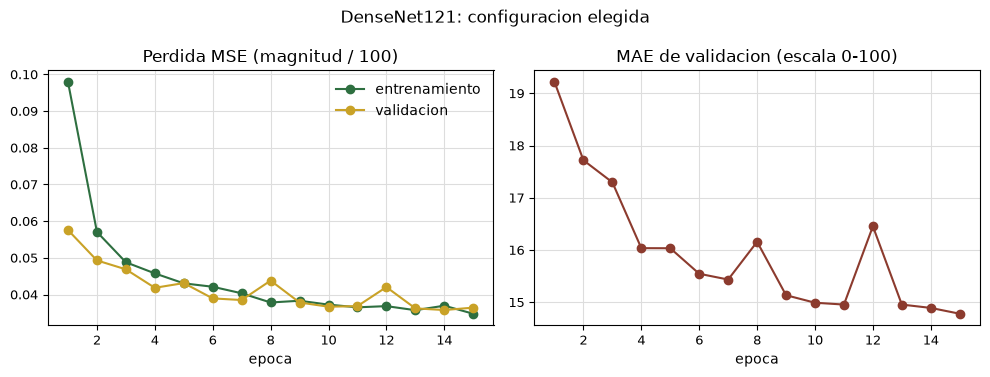

In [5]:
curva = pd.DataFrame([punto.model_dump() for punto in resultados.curva_entrenamiento])
fig, (ax_perdida, ax_mae) = plt.subplots(1, 2, figsize=(10, 3.8))
ax_perdida.plot(curva["epoca"], curva["perdida_entrenamiento"], marker="o", color=PALETA["principal"], label="entrenamiento")
ax_perdida.plot(curva["epoca"], curva["perdida_validacion"], marker="o", color=PALETA["secundario"], label="validacion")
ax_perdida.set_title("Perdida MSE (magnitud / 100)")
ax_perdida.set_xlabel("epoca")
ax_perdida.legend()
ax_mae.plot(curva["epoca"], curva["mae_validacion"], marker="o", color=PALETA["terciario"])
ax_mae.set_title("MAE de validacion (escala 0-100)")
ax_mae.set_xlabel("epoca")
for ax in (ax_perdida, ax_mae):
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
fig.suptitle("DenseNet121: configuracion elegida")
fig.tight_layout()
guardar_figura(fig, "05_curva_densenet")
curva.round(4)

## Resultados sobre la prueba

El alcance DR mide la tarea que aprende la red. El alcance global agrega los registros con otro
diagnostico, a los que la regla asigna magnitud 0.

In [6]:
tabla = tabla_predicciones(resultados)
es_sequia = tabla["dano"] == "DR"
pd.DataFrame(
    {"DR": metricas(tabla.loc[es_sequia, "real"], tabla.loc[es_sequia, "predicho"]),
     "global": metricas(tabla["real"], tabla["predicho"])}
).T.round(3)

,n,mae,rmse,r2
DR,834.0,15.582,19.358,0.354
global,4628.0,2.808,8.218,0.806


## Prediccion media por magnitud real

Si la red ordena bien las fotografias por severidad, la prediccion media debe crecer con la magnitud
real. La distancia entre ambas columnas muestra si comprime sus estimaciones hacia el centro de la
escala.

In [7]:
sequia = tabla.loc[es_sequia].assign(error_absoluto=lambda d: (d["predicho"] - d["real"]).abs())
por_magnitud = sequia.groupby("real").agg(n=("predicho", "size"), prediccion_media=("predicho", "mean"), mae=("error_absoluto", "mean"))
cercania = {f"a {umbral} puntos o menos": (sequia["error_absoluto"] <= umbral).mean() for umbral in (10, 20)}
print({clave: f"{100 * valor:.1f} %" for clave, valor in cercania.items()})
por_magnitud.round(2)

{'a 10 puntos o menos': '39.0 %', 'a 20 puntos o menos': '68.6 %'}


,n,prediccion_media,mae
real,,,
10.0,135,30.41,21.12
20.0,128,34.76,16.26
30.0,129,37.54,12.46
40.0,131,42.79,11.17
50.0,96,50.14,9.35
60.0,75,56.27,11.17
70.0,33,52.35,17.78
80.0,54,60.29,20.67
90.0,44,61.86,28.59
